# Badminton Player Analytics – Linear Regression Model
**Target Variable :** `Win Rate %`  
**Model :** Linear Regression  


In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

In [55]:
df = pd.read_csv('Badminton_Dataset_CLEANED.csv')
df.columns = df.columns.str.strip()

##  Feature Engineering

In [56]:
le = LabelEncoder()
df['Handedness_enc']   = le.fit_transform(df['Handedness'].astype(str))
df['PlayingStyle_enc'] = le.fit_transform(df['Playing style'].astype(str))
df['Category_enc']     = le.fit_transform(df['Category Full'].astype(str))
feature_cols = [
    'Age', 'Height(cm)', 'Smash Speed kmh', 'Smash Success %',
    'Unforced error %', 'Agility Score', 'Stamina Index',
    'Net Play Score', 'Career Titles', 'Years Active',
    'Rally Win Rate %', 'Ranking points',
    'Handedness_enc', 'PlayingStyle_enc', 'Category_enc'
]
target = 'Win Rate %'
df_model = df[feature_cols + [target]].dropna()
X = df_model[feature_cols]
y = df_model[target]
print(f'Samples  : {len(df_model)}  |  Features : {len(feature_cols)}')
print(f'Target   : {target}  |  Mean = {y.mean():.2f}  |  Std = {y.std():.2f}')

Samples  : 100  |  Features : 15
Target   : Win Rate %  |  Mean = 66.70  |  Std = 5.28


##  Train / Test Split

In [57]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f'Training samples : {len(X_train)}')
print(f'Testing  samples : {len(X_test)}')

Training samples : 80
Testing  samples : 20


##  Feature Scaling

In [58]:
scaler     = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

##  Train Linear Regression Model

In [59]:
lr = LinearRegression()
lr.fit(X_train_sc, y_train)

y_pred_train = lr.predict(X_train_sc)
y_pred_test  = lr.predict(X_test_sc)

##  Evaluation Metrics

In [60]:
r2_train = r2_score(y_train, y_pred_train)
r2_test  = r2_score(y_test,  y_pred_test)
mae      = mean_absolute_error(y_test, y_pred_test)
rmse     = np.sqrt(mean_squared_error(y_test, y_pred_test))
print('       LINEAR REGRESSION – RESULTS')

print(f'  Training R²  : {r2_train:.4f}')
print(f'  Test     R²  : {r2_test:.4f}')
print(f'  Test     MAE : {mae:.4f}')
print(f'  Test     RMSE: {rmse:.4f}')


       LINEAR REGRESSION – RESULTS
  Training R²  : 0.9914
  Test     R²  : 0.9816
  Test     MAE : 0.5940
  Test     RMSE: 0.7958


## Plot – Actual vs Predicted & Residuals vs Predicted

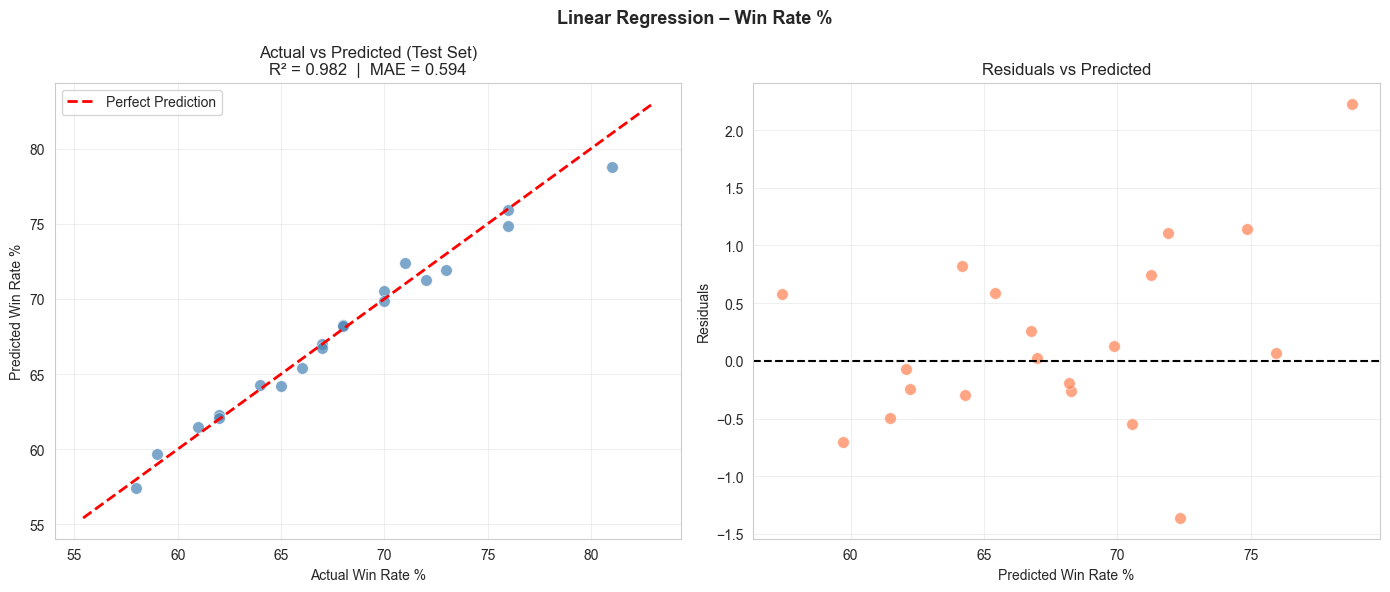

In [61]:
residuals = y_test - y_pred_test
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].scatter(y_test, y_pred_test,
                alpha=0.7, color='steelblue', edgecolors='white',
                linewidth=0.5, s=70)
lo = min(y_test.min(), y_pred_test.min()) - 2
hi = max(y_test.max(), y_pred_test.max()) + 2
axes[0].plot([lo, hi], [lo, hi], 'r--', linewidth=2, label='Perfect Prediction')
axes[0].set_xlabel('Actual Win Rate %')
axes[0].set_ylabel('Predicted Win Rate %')
axes[0].set_title(f'Actual vs Predicted (Test Set)\nR² = {r2_test:.3f}  |  MAE = {mae:.3f}')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[1].scatter(y_pred_test, residuals,
                alpha=0.7, color='coral', edgecolors='white',
                linewidth=0.5, s=70)
axes[1].axhline(0, color='black', linestyle='--', linewidth=1.5)
axes[1].set_xlabel('Predicted Win Rate %')
axes[1].set_ylabel('Residuals')
axes[1].set_title('Residuals vs Predicted')
axes[1].grid(True, alpha=0.3)
plt.suptitle('Linear Regression – Win Rate %', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('actual_vs_predicted.png', dpi=150, bbox_inches='tight')
plt.show()

##  Plot – Residual Distribution & Train vs Test R²

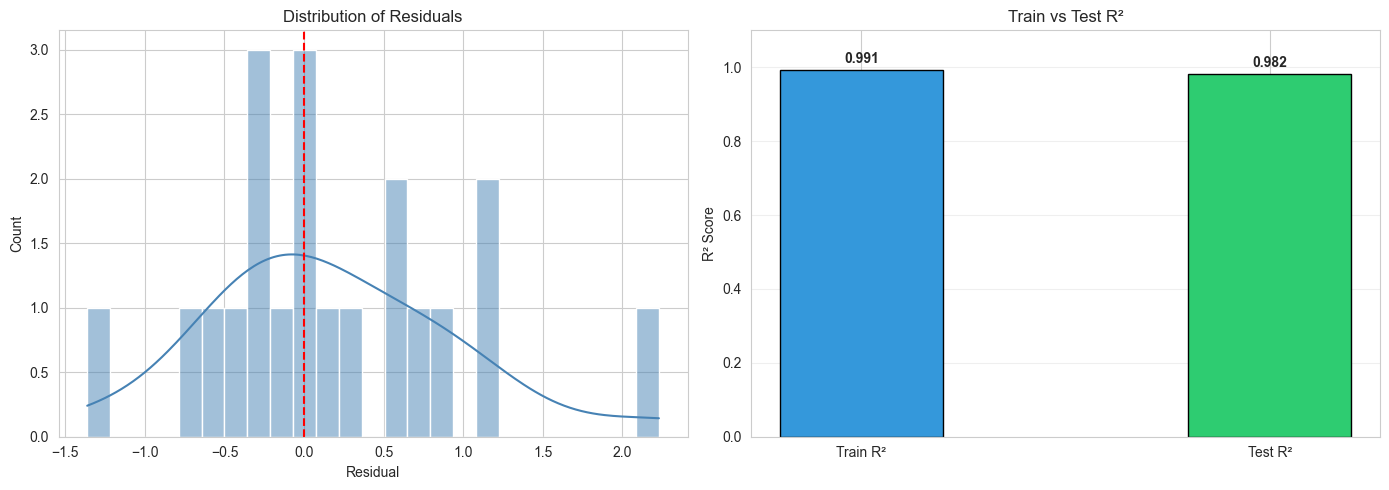

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(residuals, bins=25, kde=True, ax=axes[0], color='steelblue')
axes[0].axvline(0, color='red', linestyle='--')
axes[0].set_xlabel('Residual')
axes[0].set_title('Distribution of Residuals')
bars = axes[1].bar(
    ['Train R²', 'Test R²'],
    [r2_train, r2_test],
    color=['#3498db', '#2ecc71'],
    width=0.4,
    edgecolor='black'
)
axes[1].set_ylim(0, 1.1)
axes[1].set_ylabel('R² Score')
axes[1].set_title('Train vs Test R²')
for bar in bars:
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f'{bar.get_height():.3f}',
        ha='center', fontweight='bold'
    )
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('residuals_r2.png', dpi=150, bbox_inches='tight')
plt.show()

##  Plot – Standardised Residuals & Scale-Location

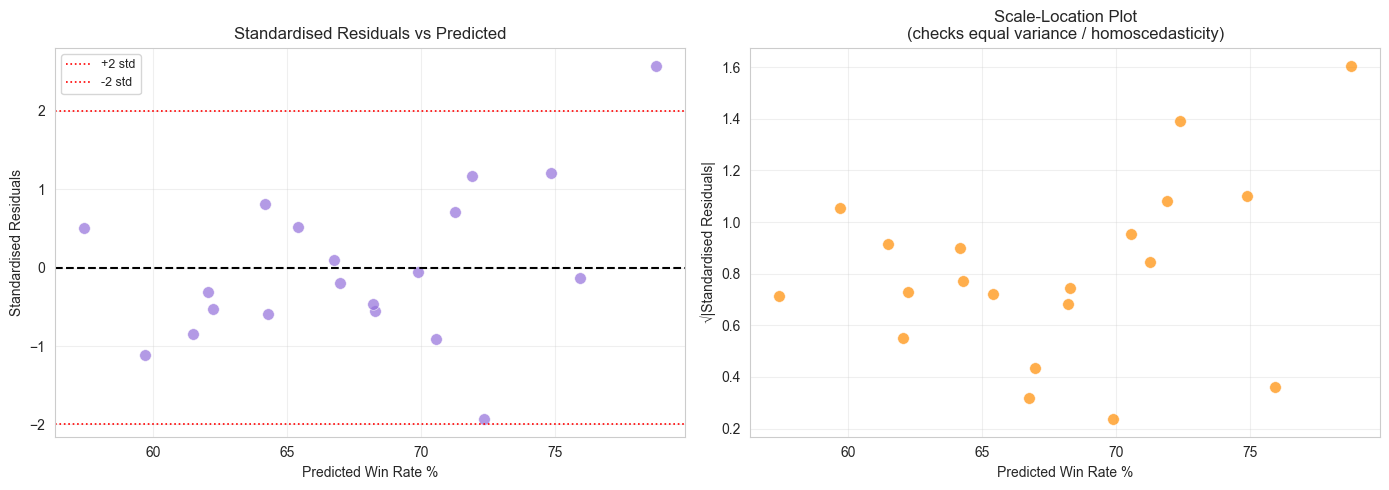

In [63]:
residuals_std = (residuals - residuals.mean()) / residuals.std()
sqrt_abs_res  = np.sqrt(np.abs(residuals_std))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_pred_test, residuals_std,
                alpha=0.7, color='mediumpurple', edgecolors='white',
                linewidth=0.5, s=70)
axes[0].axhline(0,  color='black', linestyle='--', linewidth=1.5)
axes[0].axhline( 2, color='red',   linestyle=':',  linewidth=1.2, label='+2 std')
axes[0].axhline(-2, color='red',   linestyle=':',  linewidth=1.2, label='-2 std')
axes[0].set_xlabel('Predicted Win Rate %')
axes[0].set_ylabel('Standardised Residuals')
axes[0].set_title('Standardised Residuals vs Predicted')
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)
axes[1].scatter(y_pred_test, sqrt_abs_res,
                alpha=0.7, color='darkorange', edgecolors='white',
                linewidth=0.5, s=70)
axes[1].set_xlabel('Predicted Win Rate %')
axes[1].set_ylabel('√|Standardised Residuals|')
axes[1].set_title('Scale-Location Plot\n(checks equal variance / homoscedasticity)')
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('std_residuals.png', dpi=150, bbox_inches='tight')
plt.show()